In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlretrieve
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [4]:
import pandas as pd
import zipfile
import io

filename = next(iter(uploaded))

if filename.endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(uploaded[filename])) as z:
        excel_file = next(
            name for name in z.namelist()
            if name.lower().endswith(".xlsx")
        )
        with z.open(excel_file) as f:
            df = pd.read_excel(f)

elif filename.endswith(".xlsx"):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))

else:
    raise ValueError("Please upload a .zip or .xlsx file.")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom


In [5]:
# Check the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset size:", df.shape)

Number of rows: 541909
Number of columns: 8
Dataset size: (541909, 8)


In [6]:
# Display the first five rows

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom


In [7]:
# Display all column names

print("Column names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [8]:
# Count missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_summary)

,Missing Values,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [9]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:",
      round(duplicate_count / len(df) * 100, 2), "%")

Number of duplicate rows: 5268
Duplicate percentage: 0.97 %


In [10]:
# Summary of numerical columns

display(df.describe())

# Summary of categorical columns
display(df.describe(include="object"))

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386048,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [11]:
# Convert invoice dates to datetime format

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())

print("\nNumber of unique customers:",
      df["CustomerID"].nunique())

print("Number of unique products:",
      df["StockCode"].nunique())

print("\nTop 10 countries by transaction rows:")
display(df["Country"].value_counts().head(10))

print("\nSample invoice numbers:")
display(df["InvoiceNo"].head(10))

Earliest transaction: 2010-12-01 08:26:00
Latest transaction: 2011-12-09 12:50:00

Number of unique customers: 4372
Number of unique products: 4070

Top 10 countries by transaction rows:


,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519



Sample invoice numbers:


,InvoiceNo
0,536365
1,536365
2,536365
3,536365
4,536365
5,536365
6,536365
7,536366
8,536366
9,536367


In [12]:
# Step 2.1: Create a working copy

import pandas as pd
import numpy as np

df_raw = df.copy()

# Check required columns
required_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]

missing_columns = set(required_columns) - set(df_raw.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Original dataset shape:", df_raw.shape)

# Missing values
print("\nMissing values per column:")
display(df_raw.isnull().sum().to_frame("Missing Count"))

# Duplicate records
print("\nExact duplicate rows:", df_raw.duplicated().sum())

# Data types
print("\nColumn data types:")
print(df_raw.dtypes)

Original dataset shape: (541909, 8)

Missing values per column:


,Missing Count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Exact duplicate rows: 5268

Column data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [13]:
# Step 2.2: Clean transaction records

df_clean = df_raw.copy()

# Correct data types
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype("string").str.strip()
df_clean["StockCode"] = df_clean["StockCode"].astype("string").str.strip()
df_clean["Country"] = df_clean["Country"].astype("string").str.strip()

df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

df_clean["CustomerID"] = pd.to_numeric(
    df_clean["CustomerID"], errors="coerce"
)

# Remove exact duplicates
df_clean = df_clean.drop_duplicates().copy()

# Remove records without essential transaction information
df_clean = df_clean.dropna(
    subset=["InvoiceNo", "InvoiceDate", "CustomerID",
            "Quantity", "UnitPrice"]
).copy()

# Normalize customer IDs
df_clean["CustomerID"] = df_clean["CustomerID"].astype("int64")

# Fill missing descriptive fields
df_clean["Description"] = (
    df_clean["Description"].fillna("Unknown")
)
df_clean["Country"] = df_clean["Country"].fillna("Unknown")

# Identify cancelled invoices
df_clean["IsCancelled"] = (
    df_clean["InvoiceNo"].str.upper().str.startswith("C", na=False)
)

# Identify valid purchase lines
df_clean["IsValidSale"] = (
    ~df_clean["IsCancelled"]
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
)

print("Shape after basic cleaning:", df_clean.shape)
print("Cancelled invoice rows:", df_clean["IsCancelled"].sum())
print("Valid purchase rows:", df_clean["IsValidSale"].sum())

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum().to_frame("Missing Count"))

Shape after basic cleaning: (401604, 10)
Cancelled invoice rows: 8872
Valid purchase rows: 392692

Missing values after cleaning:


,Missing Count
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
IsCancelled,0
IsValidSale,0


In [14]:
# Step 2.3: Detect outliers using the IQR method

def show_iqr_outliers(data, column):
    values = data[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((values < lower) | (values > upper)).sum()

    print(f"\nColumn: {column}")
    print("Lower bound:", round(lower, 2))
    print("Upper bound:", round(upper, 2))
    print("Outlier count:", int(count))

show_iqr_outliers(df_clean, "Quantity")
show_iqr_outliers(df_clean, "UnitPrice")


Column: Quantity
Lower bound: -13.0
Upper bound: 27.0
Outlier count: 26646

Column: UnitPrice
Lower bound: -2.5
Upper bound: 7.5
Outlier count: 35802


In [15]:
# Step 2.4: Define historical and future periods

max_date = df_clean["InvoiceDate"].max()
cutoff_date = max_date - pd.Timedelta(days=30)

print("Last dataset date:", max_date)
print("Historical period ends before:", cutoff_date)
print("Target period starts at:", cutoff_date)
print("Target period ends at:", max_date)

# Historical data: before the cutoff
history = df_clean[
    df_clean["InvoiceDate"] < cutoff_date
].copy()

# Future data: the following 30-day observation window
future = df_clean[
    (df_clean["InvoiceDate"] >= cutoff_date)
    & (df_clean["InvoiceDate"] <= max_date)
].copy()

# Use valid sales for purchase behavior
history_sales = history[history["IsValidSale"]].copy()
future_sales = future[future["IsValidSale"]].copy()

print("\nHistorical valid purchase rows:", len(history_sales))
print("Future valid purchase rows:", len(future_sales))

Last dataset date: 2011-12-09 12:50:00
Historical period ends before: 2011-11-09 12:50:00
Target period starts at: 2011-11-09 12:50:00
Target period ends at: 2011-12-09 12:50:00

Historical valid purchase rows: 328431
Future valid purchase rows: 64261


In [16]:
# Count distinct future purchase invoices for each customer

future_orders = (
    future_sales.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .rename("FutureOrders")
)

# Start with customers who have historical purchase activity
customer_ids = history_sales["CustomerID"].unique()

target_df = pd.DataFrame({"CustomerID": customer_ids})

target_df = target_df.merge(
    future_orders,
    on="CustomerID",
    how="left"
)

target_df["FutureOrders"] = (
    target_df["FutureOrders"].fillna(0).astype(int)
)

# Create the three classes
target_df["Performance"] = np.select(
    [
        target_df["FutureOrders"] == 0,
        target_df["FutureOrders"] == 1,
        target_df["FutureOrders"] >= 2
    ],
    ["Low", "Medium", "High"],
    default="Low"
)

print("Performance class distribution:")
display(target_df["Performance"].value_counts().to_frame("Customers"))

print("\nTarget sample:")
display(target_df.head())

Performance class distribution:


,Customers
Performance,
Low,2690
Medium,870
High,510



Target sample:


,CustomerID,FutureOrders,Performance
0,17850,0,Low
1,13047,0,Low
2,12583,2,High
3,13748,0,Low
4,15100,0,Low


In [17]:
# Step 2.5: Build customer-level features from historical sales

sales = history_sales.copy()

# Revenue for each transaction line
sales["LineTotal"] = sales["Quantity"] * sales["UnitPrice"]

# Invoice-level information
invoice_level = (
    sales.groupby(["CustomerID", "InvoiceNo"], as_index=False)
    .agg(
        InvoiceTotal=("LineTotal", "sum"),
        InvoiceDate=("InvoiceDate", "min")
    )
)

invoice_level["IsWeekend"] = (
    invoice_level["InvoiceDate"].dt.dayofweek >= 5
)

# Basic customer-level statistics
features = (
    sales.groupby("CustomerID")
    .agg(
        total_spending=("LineTotal", "sum"),
        total_quantity=("Quantity", "sum"),
        average_quantity_per_line=("Quantity", "mean"),
        unique_products=("StockCode", "nunique"),
        average_unit_price=("UnitPrice", "mean"),
        active_purchase_days=(
            "InvoiceDate",
            lambda s: s.dt.normalize().nunique()
        )
    )
)

# Invoice-level statistics
invoice_stats = (
    invoice_level.groupby("CustomerID")
    .agg(
        total_orders=("InvoiceNo", "nunique"),
        average_order_value=("InvoiceTotal", "mean"),
        weekend_orders=("IsWeekend", "sum"),
        first_purchase_date=("InvoiceDate", "min"),
        last_purchase_date=("InvoiceDate", "max")
    )
)

features = features.join(invoice_stats)

# Recency and customer lifetime at the cutoff
features["recency_days"] = (
    cutoff_date - features["last_purchase_date"]
).dt.total_seconds() / 86400

features["customer_lifetime_days"] = (
    features["last_purchase_date"]
    - features["first_purchase_date"]
).dt.total_seconds() / 86400

# Order frequency
features["purchase_frequency"] = (
    features["total_orders"]
    / (features["customer_lifetime_days"] + 1)
)

# Average number of days between distinct purchase dates
def average_days_between_orders(dates):
    dates = dates.sort_values().drop_duplicates()
    differences = dates.diff().dt.total_seconds() / 86400
    return differences.mean()

avg_days = (
    invoice_level.groupby("CustomerID")["InvoiceDate"]
    .apply(average_days_between_orders)
    .rename("avg_days_between_orders")
)

features = features.join(avg_days)

# Historical cancelled invoices
cancelled_history = history[history["IsCancelled"]].copy()

cancel_counts = (
    cancelled_history.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .rename("total_cancelled_orders")
)

features = features.join(cancel_counts)

# Customers with no recorded cancellations get zero
features["total_cancelled_orders"] = (
    features["total_cancelled_orders"].fillna(0)
)

# Most recently recorded country from historical sales
country_feature = (
    sales.sort_values("InvoiceDate")
    .groupby("CustomerID")["Country"]
    .last()
    .rename("country")
)

features = features.join(country_feature)

# Fill country if missing
features["country"] = features["country"].fillna("Unknown")

# Remove date helper columns; keep engineered numerical features
features = features.drop(
    columns=["first_purchase_date", "last_purchase_date"]
)

# Attach the future target
model_df = features.reset_index().merge(
    target_df[["CustomerID", "Performance"]],
    on="CustomerID",
    how="inner"
)

print("Customer-level dataset shape:", model_df.shape)
print("\nPredictor columns:")
print(features.columns.tolist())

print("\nNumber of predictor features:", len(features.columns))
display(model_df.head())

Customer-level dataset shape: (4070, 17)

Predictor columns:
['total_spending', 'total_quantity', 'average_quantity_per_line', 'unique_products', 'average_unit_price', 'active_purchase_days', 'total_orders', 'average_order_value', 'weekend_orders', 'recency_days', 'customer_lifetime_days', 'purchase_frequency', 'avg_days_between_orders', 'total_cancelled_orders', 'country']

Number of predictor features: 15


,CustomerID,total_spending,total_quantity,average_quantity_per_line,unique_products,average_unit_price,active_purchase_days,total_orders,average_order_value,weekend_orders,recency_days,customer_lifetime_days,purchase_frequency,avg_days_between_orders,total_cancelled_orders,country,Performance
0,12346,77183.60,74215,74215.00,1,1.04,1,1,77183.60,0,295.12,0.00,1.00,NaN,1.00,United Kingdom,Low
1,12347,4085.18,2266,13.25,100,2.73,6,6,680.86,0,9.02,327.89,0.02,65.58,0.00,Iceland,Medium
2,12348,1797.24,2341,75.52,22,5.76,4,4,449.31,1,44.98,282.75,0.01,94.25,0.00,Finland,Low
3,12350,334.40,197,11.59,17,3.84,1,1,334.40,0,279.87,0.00,1.00,NaN,0.00,Norway,Low
4,12352,2506.04,536,6.31,59,15.93,7,8,313.25,0,5.93,260.09,0.03,37.16,3.00,Norway,Low


In [18]:
# Step 2.6: Check missing values and duplicates in the new dataset

print("Duplicate customer rows:", model_df["CustomerID"].duplicated().sum())

print("\nMissing values:")
display(model_df.isnull().sum().to_frame("Missing Count"))

print("\nTarget class counts:")
display(model_df["Performance"].value_counts())

print("\nFeature data types:")
print(model_df.dtypes)

Duplicate customer rows: 0

Missing values:


,Missing Count
CustomerID,0
total_spending,0
total_quantity,0
average_quantity_per_line,0
unique_products,0
average_unit_price,0
active_purchase_days,0
total_orders,0
average_order_value,0
weekend_orders,0



Target class counts:


,count
Performance,
Low,2690
Medium,870
High,510



Feature data types:
CustomerID                            int64
total_spending                      float64
total_quantity                        int64
average_quantity_per_line           float64
unique_products                       int64
average_unit_price                  float64
active_purchase_days                  int64
total_orders                          int64
average_order_value                 float64
weekend_orders                        int64
recency_days                        float64
customer_lifetime_days              float64
purchase_frequency                  float64
avg_days_between_orders             float64
total_cancelled_orders              float64
country                      string[python]
Performance                          object
dtype: object


In [19]:
# Step 2.7: Separate predictors and target

from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["CustomerID", "Performance"])
y = model_df["Performance"]

# First: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second: divide the temporary set equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining class distribution:")
display(y_train.value_counts())

print("\nValidation class distribution:")
display(y_val.value_counts())

print("\nTest class distribution:")
display(y_test.value_counts())

Training samples: 2849
Validation samples: 610
Test samples: 611

Training class distribution:


,count
Performance,
Low,1883
Medium,609
High,357



Validation class distribution:


,count
Performance,
Low,403
Medium,130
High,77



Test class distribution:


,count
Performance,
Low,404
Medium,131
High,76


In [20]:
# Step 2.8: Learn outlier limits from training data only

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

cap_bounds = {}

for col in numeric_features:
    lower = X_train[col].quantile(0.01)
    upper = X_train[col].quantile(0.99)
    cap_bounds[col] = (lower, upper)

def cap_outliers(data, bounds):
    result = data.copy()

    for col, (lower, upper) in bounds.items():
        result[col] = result[col].clip(
            lower=lower,
            upper=upper
        )

    return result

X_train_capped = cap_outliers(X_train, cap_bounds)
X_val_capped = cap_outliers(X_val, cap_bounds)
X_test_capped = cap_outliers(X_test, cap_bounds)

print("Outlier limits learned from training data.")
display(pd.DataFrame(
    cap_bounds,
    index=["Lower 1% limit", "Upper 99% limit"]
).T)

Outlier limits learned from training data.


,Lower 1% limit,Upper 99% limit
total_spending,53.15,14931.01
total_quantity,10.96,8965.24
average_quantity_per_line,1.42,248.68
unique_products,1.00,301.52
average_unit_price,0.67,14.56
active_purchase_days,1.00,21.00
total_orders,1.00,24.00
average_order_value,47.02,2038.96
weekend_orders,0.00,5.00
recency_days,0.14,341.78


In [21]:
# Step 2.9: Encoding, scaling, and imputation

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_features = X_train_capped.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_features = X_train_capped.select_dtypes(
    include=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train_capped)

# Apply the fitted preprocessing to validation and test data
X_val_processed = preprocessor.transform(X_val_capped)
X_test_processed = preprocessor.transform(X_test_capped)

print("Training input shape:", X_train_processed.shape)
print("Validation input shape:", X_val_processed.shape)
print("Test input shape:", X_test_processed.shape)

Training input shape: (2849, 48)
Validation input shape: (610, 48)
Test input shape: (611, 48)


In [22]:
# Step 2.10: Encode target labels

class_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

y_train_encoded = y_train.map(class_mapping).to_numpy()
y_val_encoded = y_val.map(class_mapping).to_numpy()
y_test_encoded = y_test.map(class_mapping).to_numpy()

print("Class mapping:", class_mapping)

print("\nEncoded training labels:")
print(np.unique(y_train_encoded, return_counts=True))

print("\nEncoded validation labels:")
print(np.unique(y_val_encoded, return_counts=True))

print("\nEncoded test labels:")
print(np.unique(y_test_encoded, return_counts=True))

Class mapping: {'Low': 0, 'Medium': 1, 'High': 2}

Encoded training labels:
(array([0, 1, 2]), array([1883,  609,  357]))

Encoded validation labels:
(array([0, 1, 2]), array([403, 130,  77]))

Encoded test labels:
(array([0, 1, 2]), array([404, 131,  76]))


In [23]:
# Step 2.11: Save the processed customer-level dataset

model_df.to_csv(
    "ecommerce_customer_features.csv",
    index=False
)

print("Saved: ecommerce_customer_features.csv")

Saved: ecommerce_customer_features.csv


In [24]:
# Step 3.1: Prepare data for EDA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Make a copy of the original transaction data
eda_df = df.copy()

# Ensure correct data types
eda_df["InvoiceDate"] = pd.to_datetime(
    eda_df["InvoiceDate"], errors="coerce"
)
eda_df["Quantity"] = pd.to_numeric(
    eda_df["Quantity"], errors="coerce"
)
eda_df["UnitPrice"] = pd.to_numeric(
    eda_df["UnitPrice"], errors="coerce"
)

# Calculate transaction-line revenue
eda_df["Revenue"] = eda_df["Quantity"] * eda_df["UnitPrice"]

# Define completed positive-quantity sales for sales charts
eda_sales = eda_df[
    eda_df["InvoiceDate"].notna()
    & eda_df["Quantity"].gt(0)
    & eda_df["UnitPrice"].gt(0)
    & ~eda_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Original transaction rows:", len(eda_df))
print("Valid positive-sales rows:", len(eda_sales))
print("EDA data preparation completed.")

Original transaction rows: 541909
Valid positive-sales rows: 530104
EDA data preparation completed.


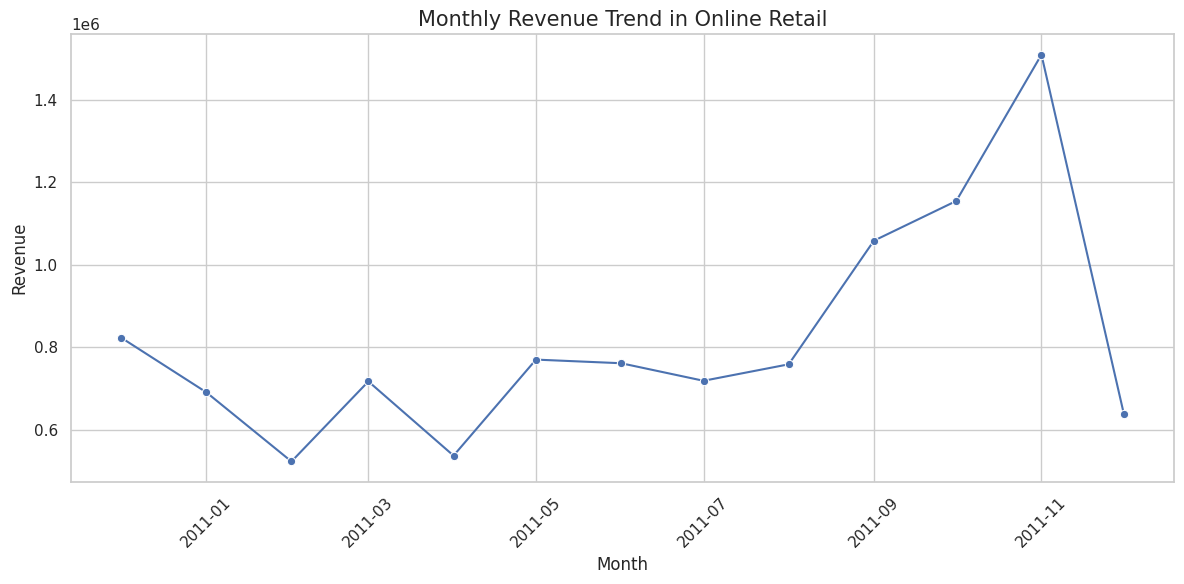

In [25]:
# Step 3.2: Monthly revenue trend

monthly_revenue = (
    eda_sales
    .assign(Month=eda_sales["InvoiceDate"].dt.to_period("M").dt.to_timestamp())
    .groupby("Month", as_index=False)["Revenue"]
    .sum()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend in Online Retail", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

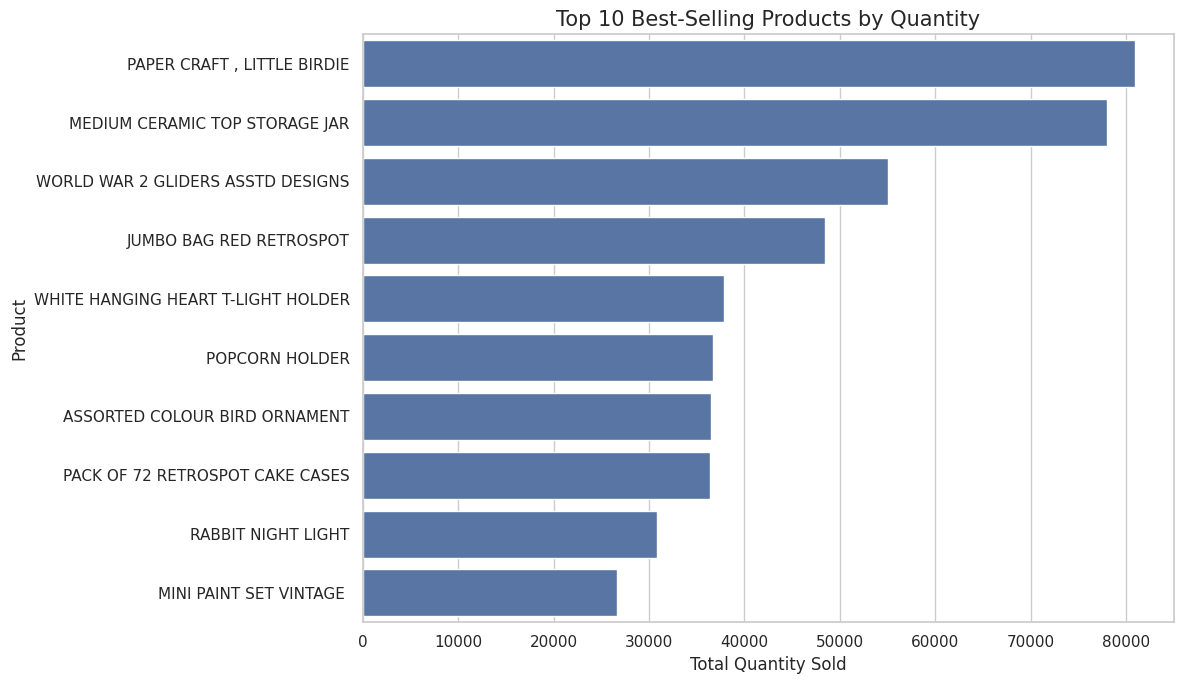

,Description,Quantity
2387,"PAPER CRAFT , LITTLE BIRDIE",80995
2052,MEDIUM CERAMIC TOP STORAGE JAR,78033
3934,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
1816,JUMBO BAG RED RETROSPOT,48474
3844,WHITE HANGING HEART T-LIGHT HOLDER,37891
2681,POPCORN HOLDER,36761
227,ASSORTED COLOUR BIRD ORNAMENT,36461
2337,PACK OF 72 RETROSPOT CAKE CASES,36419
2741,RABBIT NIGHT LIGHT,30788
2107,MINI PAINT SET VINTAGE,26633


In [26]:
# Step 3.3: Top 10 products by quantity sold

product_sales = (
    eda_sales.groupby("Description", as_index=False)["Quantity"]
    .sum()
    .sort_values("Quantity", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=product_sales,
    x="Quantity",
    y="Description"
)

plt.title("Top 10 Best-Selling Products by Quantity", fontsize=15)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(product_sales)

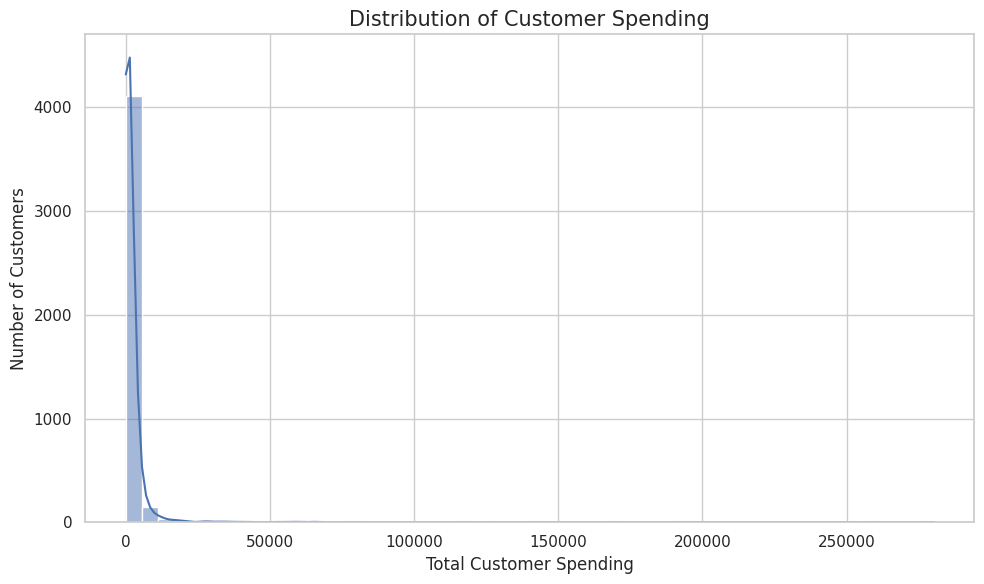

Median customer spending: 674.49
Mean customer spending: 2054.27


In [27]:
# Step 3.4: Customer spending distribution

customer_spending = (
    eda_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
)

plt.figure(figsize=(10, 6))
sns.histplot(
    customer_spending[customer_spending > 0],
    bins=50,
    kde=True
)

plt.title("Distribution of Customer Spending", fontsize=15)
plt.xlabel("Total Customer Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Median customer spending:", round(customer_spending.median(), 2))
print("Mean customer spending:", round(customer_spending.mean(), 2))

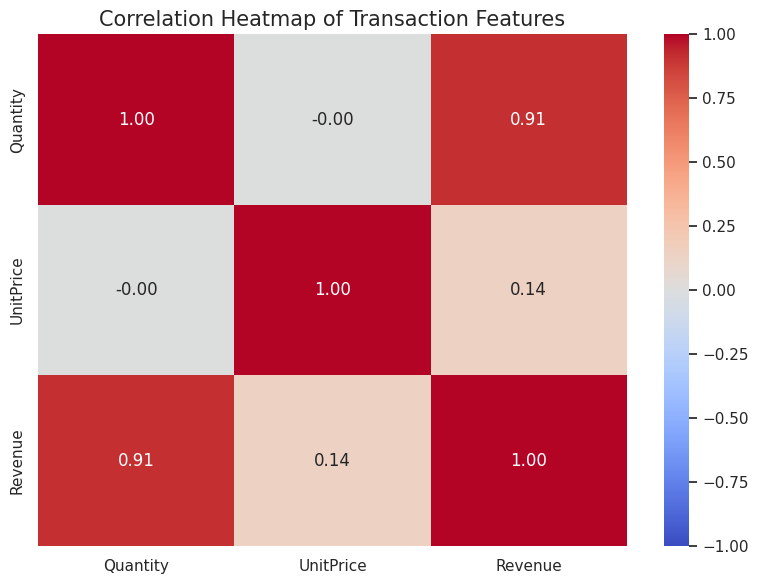

In [28]:
# Step 3.5: Numerical feature correlation heatmap

corr_data = eda_sales[
    ["Quantity", "UnitPrice", "Revenue"]
].replace([np.inf, -np.inf], np.nan).dropna()

correlation_matrix = corr_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Transaction Features", fontsize=15)
plt.tight_layout()
plt.show()

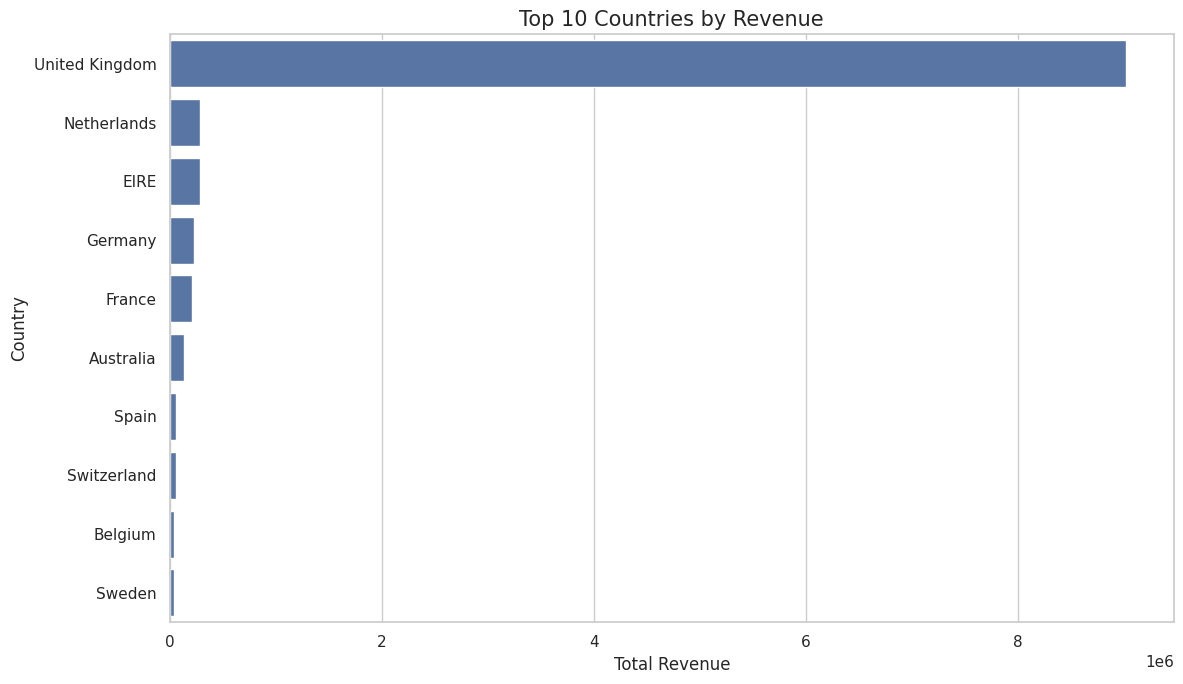

,Country,Revenue
36,United Kingdom,9025222.08
24,Netherlands,285446.34
10,EIRE,283453.96
14,Germany,228867.14
13,France,209715.11
0,Australia,138521.31
31,Spain,61577.11
33,Switzerland,57089.90
3,Belgium,41196.34
32,Sweden,38378.33


In [29]:
# Step 3.6: Top 10 countries by revenue

country_revenue = (
    eda_sales.groupby("Country", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue", fontsize=15)
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(country_revenue)

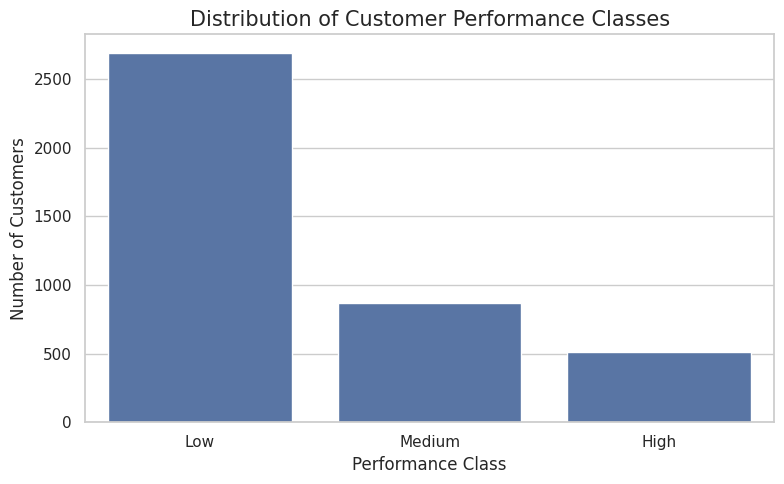

Class percentages:


,count
Performance,
Low,66.09
Medium,21.38
High,12.53


In [30]:
# Step 3.7: Distribution of the classification target

if "model_df" in globals() and "Performance" in model_df.columns:
    class_counts = (
        model_df["Performance"]
        .value_counts()
        .reindex(["Low", "Medium", "High"], fill_value=0)
    )

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=class_counts.index,
        y=class_counts.values
    )

    plt.title("Distribution of Customer Performance Classes", fontsize=15)
    plt.xlabel("Performance Class")
    plt.ylabel("Number of Customers")
    plt.tight_layout()
    plt.show()

    print("Class percentages:")
    display((class_counts / class_counts.sum() * 100).round(2))
else:
    print("model_df with a Performance column is not available.")

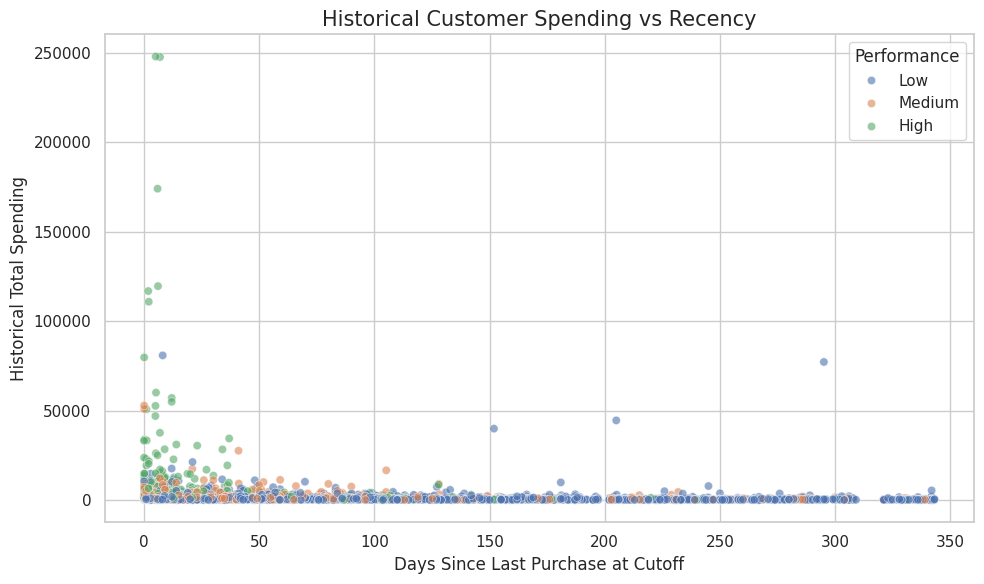

In [31]:
# Step 3.8: Recency versus total spending

if "model_df" in globals() and {
    "recency_days", "total_spending", "Performance"
}.issubset(model_df.columns):

    plot_df = model_df[
        ["recency_days", "total_spending", "Performance"]
    ].replace([np.inf, -np.inf], np.nan).dropna()

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=plot_df,
        x="recency_days",
        y="total_spending",
        hue="Performance",
        alpha=0.6
    )

    plt.title("Historical Customer Spending vs Recency", fontsize=15)
    plt.xlabel("Days Since Last Purchase at Cutoff")
    plt.ylabel("Historical Total Spending")
    plt.tight_layout()
    plt.show()
else:
    print("Required customer-level features are not available.")

In [32]:
# Step 4.1: Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: False


In [33]:
# Step 4.2: Prepare model inputs and labels

X_train_nn = np.asarray(X_train_processed, dtype=np.float32)
X_val_nn = np.asarray(X_val_processed, dtype=np.float32)
X_test_nn = np.asarray(X_test_processed, dtype=np.float32)

def encode_performance(y):
    # Convert labels to a consistent 0, 1, 2 mapping
    label_map = {
        "Low": 0,
        "Average": 1,
        "Medium": 1,
        "High": 2
    }

    values = np.asarray(y).reshape(-1)

    if len(values) == 0:
        raise ValueError("A label dataset is empty.")

    if values.dtype.kind in "iu":
        encoded = values.astype(np.int32)
    elif values.dtype.kind == "f" and np.all(values == np.floor(values)):
        encoded = values.astype(np.int32)
    else:
        normalized = pd.Series(values).astype(str).str.strip().str.title()
        encoded = normalized.map(label_map)

        if encoded.isna().any():
            raise ValueError(
                "Unexpected class labels: "
                + str(normalized[encoded.isna()].unique().tolist())
            )

        encoded = encoded.to_numpy(dtype=np.int32)

    if not np.isin(encoded, [0, 1, 2]).all():
        raise ValueError("Labels must be 0=Low, 1=Average, 2=High.")

    return encoded

y_train_nn = encode_performance(y_train)
y_val_nn = encode_performance(y_val)
y_test_nn = encode_performance(y_test)

print("Training features:", X_train_nn.shape)
print("Validation features:", X_val_nn.shape)
print("Test features:", X_test_nn.shape)

print("Training labels:", y_train_nn.shape)
print("Validation labels:", y_val_nn.shape)
print("Test labels:", y_test_nn.shape)

Training features: (2849, 48)
Validation features: (610, 48)
Test features: (611, 48)
Training labels: (2849,)
Validation labels: (610,)
Test labels: (611,)


In [34]:
# Step 4.3: Check class distribution

class_names = ["Low", "Average", "High"]

for split_name, labels in [
    ("Training", y_train_nn),
    ("Validation", y_val_nn),
    ("Test", y_test_nn)
]:
    counts = pd.Series(labels).value_counts().reindex(
        [0, 1, 2], fill_value=0
    )

    print(f"\n{split_name} class distribution:")
    print(pd.DataFrame({
        "Class": class_names,
        "Count": counts.values,
        "Percentage": (
            counts.values / len(labels) * 100
        ).round(2)
    }))

# Calculate class weights using TRAINING labels only
present_classes = np.unique(y_train_nn)

weights = compute_class_weight(
    class_weight="balanced",
    classes=present_classes,
    y=y_train_nn
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(present_classes, weights)
}

print("\nTraining class weights:", class_weights)


Training class distribution:
     Class  Count  Percentage
0      Low   1883       66.09
1  Average    609       21.38
2     High    357       12.53

Validation class distribution:
     Class  Count  Percentage
0      Low    403       66.07
1  Average    130       21.31
2     High     77       12.62

Test class distribution:
     Class  Count  Percentage
0      Low    404       66.12
1  Average    131       21.44
2     High     76       12.44

Training class weights: {0: 0.5043370508054523, 1: 1.5593869731800767, 2: 2.6601307189542482}


In [35]:
# Step 4.4: Build the MLP model

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

input_features = X_train_nn.shape[1]

def build_mlp(hidden1=64, hidden2=32, dropout_rate=0.2,
              learning_rate=0.001):

    model = Sequential([
        Input(shape=(input_features,)),
        Dense(hidden1, activation="relu"),
        Dropout(dropout_rate),
        Dense(hidden2, activation="relu"),
        Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Hyperparameter combinations to compare
configs = [
    {
        "name": "Config 1",
        "hidden1": 64,
        "hidden2": 32,
        "dropout": 0.2,
        "learning_rate": 0.001
    },
    {
        "name": "Config 2",
        "hidden1": 128,
        "hidden2": 64,
        "dropout": 0.3,
        "learning_rate": 0.001
    },
    {
        "name": "Config 3",
        "hidden1": 64,
        "hidden2": 32,
        "dropout": 0.2,
        "learning_rate": 0.0005
    }
]

results = []
histories = {}
models = {}

for config in configs:
    print("\nTraining:", config["name"])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_mlp(
        hidden1=config["hidden1"],
        hidden2=config["hidden2"],
        dropout_rate=config["dropout"],
        learning_rate=config["learning_rate"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        mode="min"
    )

    history = model.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_val_nn, y_val_nn),
        epochs=50,
        batch_size=32,
        callbacks=[early_stop],
        class_weight=class_weights,
        verbose=0
    )

    best_val_loss = min(history.history["val_loss"])
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    results.append({
        "Configuration": config["name"],
        "Best Validation Loss": best_val_loss,
        "Best Epoch": best_epoch,
        "Final Validation Accuracy": history.history["val_accuracy"][-1]
    })

    histories[config["name"]] = history
    models[config["name"]] = model

tuning_results = pd.DataFrame(results).sort_values(
    "Best Validation Loss"
).reset_index(drop=True)

display(tuning_results)

best_name = tuning_results.loc[0, "Configuration"]
best_model = models[best_name]
best_history = histories[best_name]

print("Best configuration:", best_name)
print("Selected using lowest validation loss.")


Training: Config 1

Training: Config 2

Training: Config 3


,Configuration,Best Validation Loss,Best Epoch,Final Validation Accuracy
0,Config 2,0.87,1,0.63
1,Config 3,0.88,18,0.62
2,Config 1,0.89,6,0.60


Best configuration: Config 2
Selected using lowest validation loss.


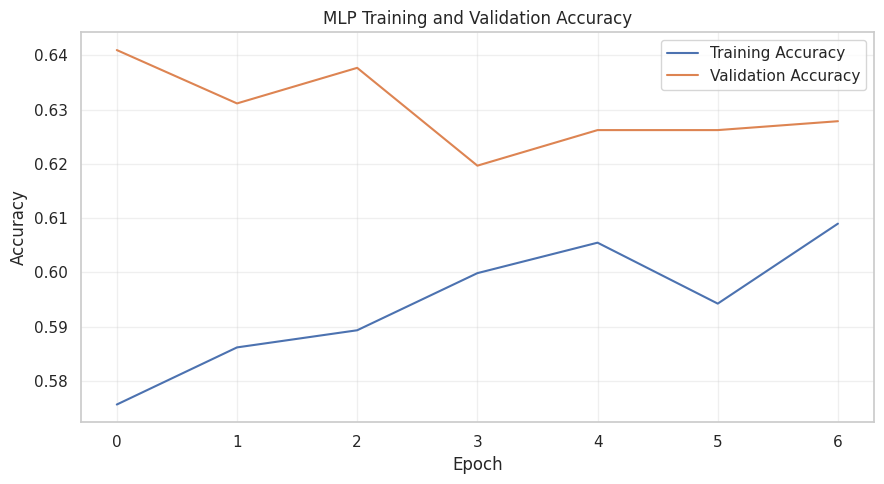

In [36]:
# Step 4.5: Accuracy versus epochs

plt.figure(figsize=(9, 5))

plt.plot(
    best_history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    best_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

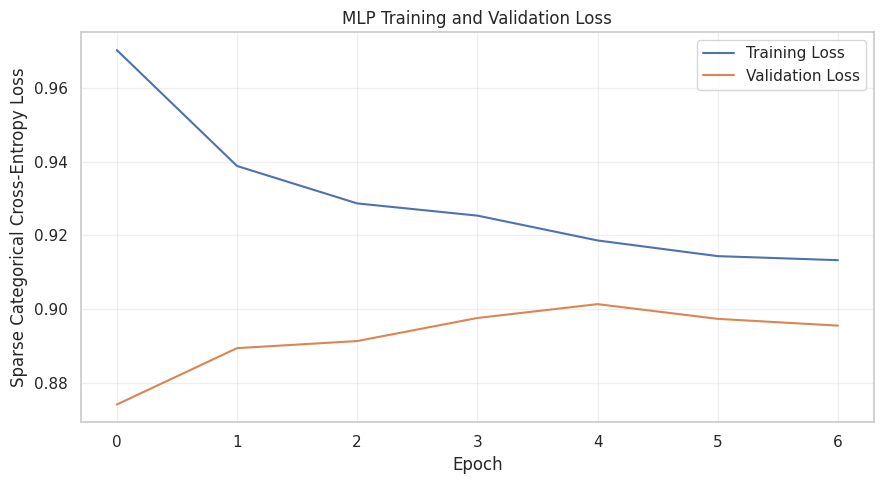

In [37]:
# Step 4.6: Loss versus epochs

plt.figure(figsize=(9, 5))

plt.plot(
    best_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    best_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Sparse Categorical Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# Step 4.7: Evaluate the selected model on validation data

val_loss, val_accuracy = best_model.evaluate(
    X_val_nn,
    y_val_nn,
    verbose=0
)

print("Best model:", best_name)
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy (%): {val_accuracy * 100:.2f}%")

Best model: Config 2
Validation Loss: 0.8741
Validation Accuracy: 0.6410
Validation Accuracy (%): 64.10%


In [39]:
# Step 4.8: Save the best model

best_model.save("ecommerce_mlp_model.keras")

print("Model saved as ecommerce_mlp_model.keras")

Model saved as ecommerce_mlp_model.keras


In [40]:
from google.colab import files

files.download("ecommerce_mlp_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
# Step 5.1: Final test evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

test_loss, test_accuracy = best_model.evaluate(
    X_test_nn,
    y_test_nn,
    verbose=0
)

print("Final Test Results")
print("------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

Final Test Results
------------------
Test Loss: 0.9442
Test Accuracy: 0.5908
Test Accuracy (%): 59.08%


In [42]:
# Step 5.2: Predict the test classes

y_test_prob = best_model.predict(X_test_nn, verbose=0)

# Choose the class with the highest predicted probability
y_test_pred = np.argmax(y_test_prob, axis=1)

class_names = ["Low", "Average", "High"]

accuracy = accuracy_score(y_test_nn, y_test_pred)
precision = precision_score(
    y_test_nn, y_test_pred,
    average="weighted", zero_division=0
)
recall = recall_score(
    y_test_nn, y_test_pred,
    average="weighted", zero_division=0
)
f1 = f1_score(
    y_test_nn, y_test_pred,
    average="weighted", zero_division=0
)

metrics_table = pd.DataFrame({
    "Metric": ["Accuracy", "Weighted Precision",
               "Weighted Recall", "Weighted F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics_table.round(4))

,Metric,Score
0,Accuracy,0.59
1,Weighted Precision,0.63
2,Weighted Recall,0.59
3,Weighted F1-score,0.60


In [43]:
# Step 5.3: Per-class evaluation

print(classification_report(
    y_test_nn,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

         Low     0.7920    0.6881    0.7364       404
     Average     0.3279    0.3053    0.3162       131
        High     0.3116    0.5658    0.4019        76

    accuracy                         0.5908       611
   macro avg     0.4772    0.5198    0.4848       611
weighted avg     0.6327    0.5908    0.6047       611



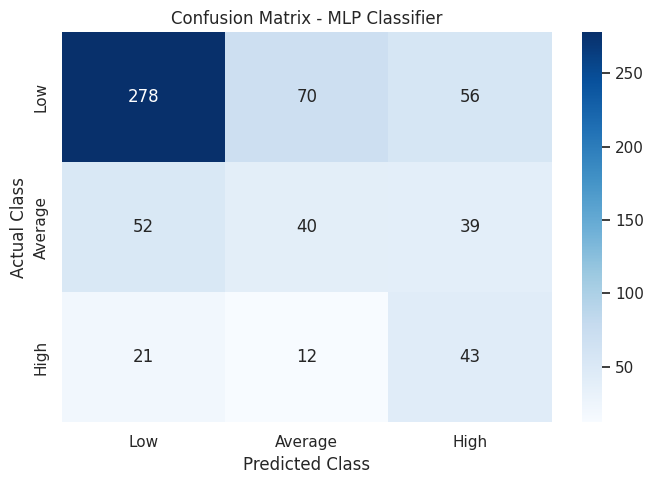

In [44]:
# Step 5.4: Confusion matrix

cm = confusion_matrix(
    y_test_nn,
    y_test_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - MLP Classifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

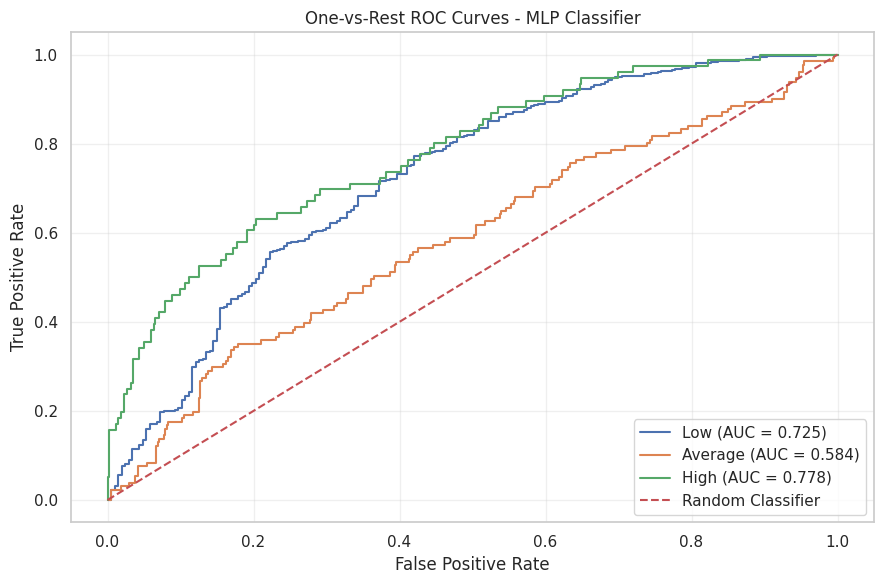

Class-wise ROC-AUC scores:
Low: 0.7246
Average: 0.5842
High: 0.7781


In [45]:
# Step 5.5: Multiclass ROC curves and AUC

y_test_onehot = label_binarize(
    y_test_nn,
    classes=[0, 1, 2]
)

plt.figure(figsize=(9, 6))

auc_scores = {}

for i, class_name in enumerate(class_names):
    # ROC requires both positive and negative examples
    if len(np.unique(y_test_onehot[:, i])) < 2:
        print(
            f"Cannot calculate ROC for {class_name}: "
            "the test set does not contain both binary outcomes."
        )
        continue

    fpr, tpr, _ = roc_curve(
        y_test_onehot[:, i],
        y_test_prob[:, i]
    )

    class_auc = auc(fpr, tpr)
    auc_scores[class_name] = class_auc

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("One-vs-Rest ROC Curves - MLP Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Class-wise ROC-AUC scores:")
for name, score in auc_scores.items():
    print(f"{name}: {score:.4f}")

In [46]:
# Step 5.6: Final evaluation summary

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-score"
    ],
    "Value": [
        test_loss,
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(evaluation_summary.round(4))

# Save the results
evaluation_summary.to_csv(
    "mlp_evaluation_summary.csv",
    index=False
)

print("Evaluation summary saved successfully.")

,Metric,Value
0,Test Loss,0.94
1,Test Accuracy,0.59
2,Weighted Precision,0.63
3,Weighted Recall,0.59
4,Weighted F1-score,0.60


Evaluation summary saved successfully.


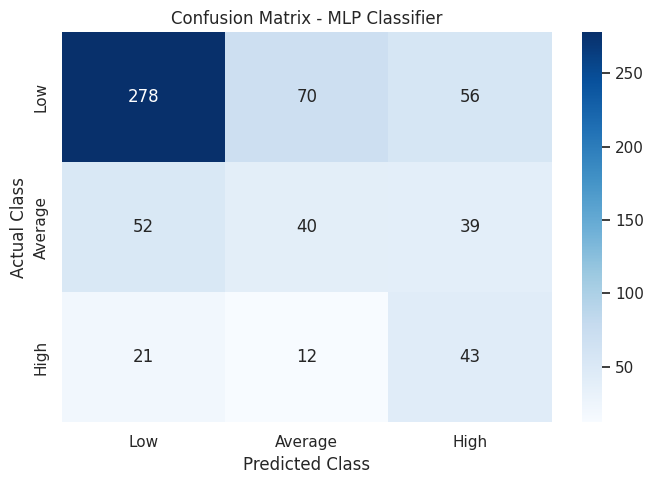

In [47]:
# Save the confusion matrix figure
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - MLP Classifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
from google.colab import files

files.download("mlp_evaluation_summary.csv")
files.download("confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

import os

# Create folders for the project outputs
os.makedirs("evaluation_results", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


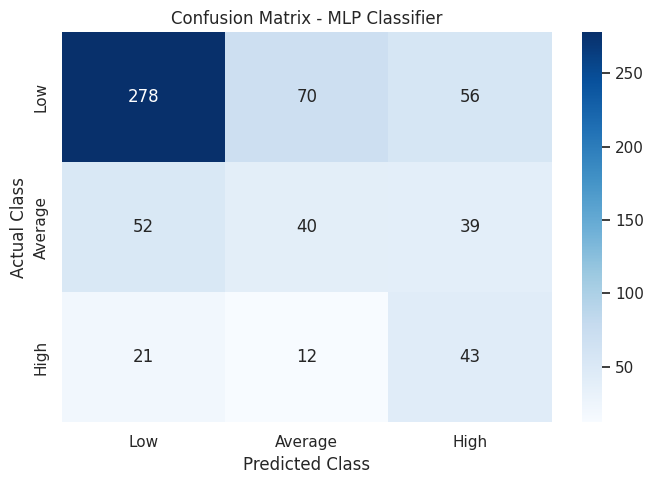

Evaluation results saved successfully!


In [50]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

os.makedirs("evaluation_results", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

# 1. Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Value": [
        float(test_loss),
        accuracy_score(y_test_nn, y_test_pred),
        precision_score(y_test_nn, y_test_pred,
                        average="weighted", zero_division=0),
        recall_score(y_test_nn, y_test_pred,
                     average="weighted", zero_division=0),
        f1_score(y_test_nn, y_test_pred,
                 average="weighted", zero_division=0)
    ]
})

metrics.to_csv(
    "evaluation_results/metrics_summary.csv",
    index=False
)

# 2. Save the classification report
report = classification_report(
    y_test_nn,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Average", "High"],
    zero_division=0,
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "evaluation_results/classification_report.csv"
)

# 3. Save actual and predicted results
predictions = pd.DataFrame({
    "Actual_Class": np.asarray(y_test_nn),
    "Predicted_Class": np.asarray(y_test_pred),
    "Low_Probability": y_test_prob[:, 0],
    "Average_Probability": y_test_prob[:, 1],
    "High_Probability": y_test_prob[:, 2]
})

predictions.to_csv(
    "evaluation_results/test_predictions.csv",
    index=False
)

# 4. Save the confusion matrix as a CSV file
cm = confusion_matrix(y_test_nn, y_test_pred, labels=[0, 1, 2])

pd.DataFrame(
    cm,
    index=["Actual_Low", "Actual_Average", "Actual_High"],
    columns=["Predicted_Low", "Predicted_Average", "Predicted_High"]
).to_csv("evaluation_results/confusion_matrix.csv")

# 5. Save the confusion matrix as an image
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Average", "High"],
    yticklabels=["Low", "Average", "High"]
)
plt.title("Confusion Matrix - MLP Classifier")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(
    "visualizations/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Evaluation results saved successfully!")


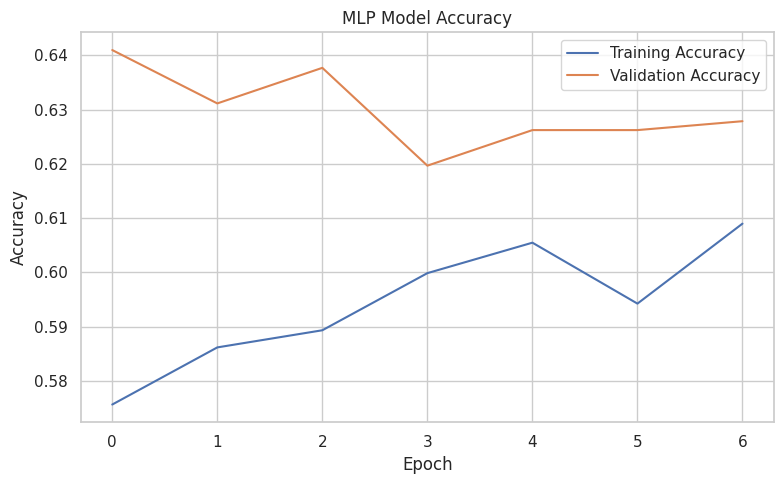

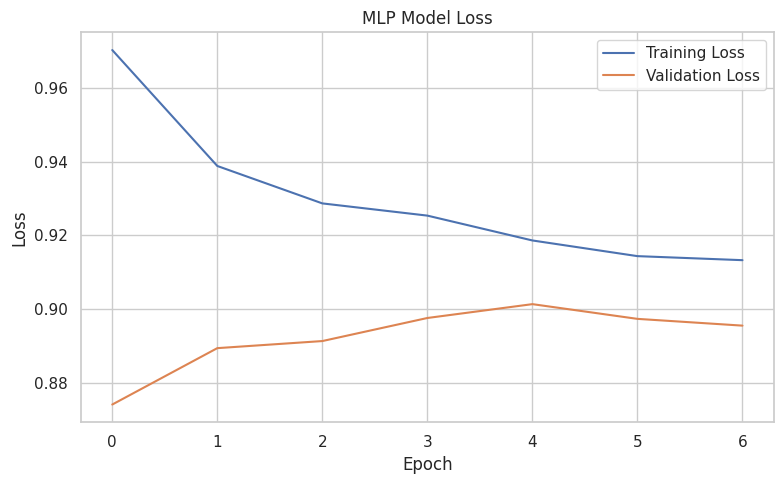

Training graphs saved successfully!


In [51]:

import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(best_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MLP Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("visualizations/model_accuracy.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(best_history.history["loss"], label="Training Loss")
plt.plot(best_history.history["val_loss"], label="Validation Loss")
plt.title("MLP Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("visualizations/model_loss.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Training graphs saved successfully!")


In [52]:

%%writefile README.md
# E-Commerce Customer Behavior and Purchase Prediction

## Project Overview
This project analyzes online retail transaction data and uses a
Multi-Layer Perceptron (MLP) deep learning model to classify
customers based on their future purchasing activity.

## Objectives
- Clean and preprocess online retail data.
- Analyze customer purchasing patterns using visualizations.
- Create customer-level features from transaction records.
- Predict Low, Average, and High future purchasing activity.
- Evaluate the model using classification metrics and graphs.

## Dataset
Source: UCI Machine Learning Repository - Online Retail

https://archive.ics.uci.edu/dataset/352/online+retail

The original dataset contains online retail transactions.
The target classes are created from the number of distinct valid
purchase invoices during the final 30 days of the dataset period.

- Low: 0 future purchase invoices
- Average: 1 future purchase invoice
- High: 2 or more future purchase invoices

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- TensorFlow / Keras
- Google Colab

## Project Structure
- ecommerce_customer_prediction.ipynb: Main notebook
- evaluation_results/: Model metrics and predictions
- visualizations/: EDA charts and model evaluation graphs
- README.md: Project documentation
- requirements.txt: Python dependencies

## How to Run
1. Open the notebook in Google Colab.
2. Download the dataset from the UCI link above.
3. Upload the dataset when prompted, or update the notebook
   to load it from your chosen location.
4. Run the notebook cells in order.

## Model Evaluation
The project reports test loss, accuracy, weighted precision,
weighted recall, weighted F1-score, a classification report,
and a confusion matrix.

Actual evaluation values are available in evaluation_results/.

## Limitations
The prediction classes are engineered from historical transactions.
They indicate future purchasing activity within this dataset and
do not directly represent website visits or conversion rates.


Writing README.md


In [53]:

%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn
tensorflow
openpyxl


Writing requirements.txt


In [54]:

import os
import zipfile

project_items = [
    "evaluation_results",
    "visualizations",
    "README.md",
    "requirements.txt",
    "ecommerce_customer_features.csv"
]

with zipfile.ZipFile("ecommerce_project_files.zip", "w",
                     zipfile.ZIP_DEFLATED) as zipf:
    for item in project_items:
        if os.path.isfile(item):
            zipf.write(item, arcname=item)
        elif os.path.isdir(item):
            for root, dirs, filenames in os.walk(item):
                for filename in filenames:
                    filepath = os.path.join(root, filename)
                    zipf.write(filepath, arcname=filepath)

print("Project output ZIP created!")


Project output ZIP created!


In [55]:

from google.colab import files
files.download("ecommerce_project_files.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>